# N2 — Influência do limiar de decisão na classificação de tumores mamários

**Instituição:** Instituto Federal de Educação, Ciência e Tecnologia do Ceará — Campus Aracati  
**Curso:** Bacharelado em Ciência da Computação  
**Disciplina:** Inteligência Artificial  
**Professor:** Gabriel Duarte  
**Aluna:** Alane Damasceno Moreno  
**Atividade:** Experimento computacional — N2  
**Ano:** 2026

## Objetivo geral
Analisar como a escolha do limiar de decisão influencia os falsos negativos, recall e F1-score na classificação de tumores malignos, comparando Regressão Logística e MLP.

## Procedimento
A base pública Wisconsin Diagnostic será dividida de forma estratificada em treinamento e teste (80/20). Ajustarei a padronização apenas no treino, dentro de cada pipeline. No conjunto de treino, utilizarei cinco partições estratificadas para produzir probabilidades fora da amostra e escolher um limiar de 0,1 a 0,9 pelo maior F1 da classe maligna (desempate: menor limiar). Por fim, avaliarei os modelos uma única vez no teste reservado.

**Limitação:** o experimento é acadêmico, não valida uso clínico.

## 1. Bibliotecas e preparação dos dados
A base original codifica maligno como zero. Vou recodificar para **1 = maligno**, para manter as métricas coerentes com a proposta.

**O que fiz:** carreguei uma base pública para que o experimento possa ser repetido sem coleta de dados. Também defini a classe maligna como positiva, já que meu foco é identificar casos malignos classificados incorretamente como benignos.


In [1]:
# Nesta etapa, importei as bibliotecas necessárias para preparar os dados, treinar os modelos e avaliar os resultados.
# O NumPy e o Pandas ajudam a organizar as informações; o Matplotlib será usado nos gráficos.
# Do scikit-learn, utilizei as ferramentas de divisão, padronização, modelagem e avaliação.

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve)

# Criei a pasta em que vou guardar os gráficos e as tabelas desta execução.
PASTA_RESULTADOS = Path("resultados")
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Usei a mesma semente nas etapas aleatórias para facilitar a reprodução do experimento.
SEMENTE = 42
# Carreguei a base pública Breast Cancer Wisconsin disponível no scikit-learn.
base = load_breast_cancer()
# Transformei os atributos em uma tabela para facilitar a conferência e o tratamento dos dados.
X = pd.DataFrame(base.data, columns=base.feature_names)
y = (base.target == 0).astype(int)  # 1=maligno, 0=benigno
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Amostras:', len(y), '| Atributos:', X.shape[1])
print('Benignos:', (y == 0).sum(), '| Malignos:', (y == 1).sum())

Python: 3.13.16 | scikit-learn: 1.6.1
Amostras: 569 | Atributos: 30
Benignos: 357 | Malignos: 212


## 2. Divisão estratificada e modelos
A Regressão Logística será o modelo de referência (*baseline*). A MLP terá duas camadas ocultas de 16 neurônios. Manterei hiperparâmetros fixos para que a comparação seja reproduzível.

**Por que fiz assim:** apliquei a mesma divisão aos dois modelos e coloquei a padronização dentro de cada pipeline. Dessa forma, as médias e os desvios usados na transformação são aprendidos somente com os dados de treino de cada ajuste. A Regressão Logística funciona como comparação básica e a MLP permite testar um modelo neural.


In [2]:
# Separei 80% das amostras para treinamento e 20% para teste.
# Usei stratify=y para preservar a proporção de tumores benignos e malignos nos dois conjuntos.
# Fixei a semente para que essa divisão possa ser reproduzida.

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE
)
# Defini os dois algoritmos que vou comparar sob o mesmo conjunto de dados.
modelos = {
    # A Regressão Logística será meu baseline (modelo de referência).
    'Regressão Logística': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEMENTE)
    ),
    # A MLP é minha rede neural, com duas camadas ocultas de 16 neurônios cada.
    'MLP': make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(16, 16),
                                       activation='relu', solver='adam',
                                       max_iter=2000, random_state=SEMENTE)
    ),
}
# Defini cinco partições estratificadas, com embaralhamento reprodutível.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
# Testarei limiares de 0,1 a 0,9, incluindo o valor padrão de 0,5.
limiares = np.round(np.arange(0.1, 1.0, 0.1), 1)
print('Treino:', len(y_treino), '| Teste reservado:', len(y_teste))

Treino: 455 | Teste reservado: 114


## 3. Função de avaliação
Além das métricas de classificação, registro explicitamente falsos positivos (FP) e falsos negativos (FN). ROC-AUC será calculada com as **probabilidades**, portanto não se altera apenas por mudar o limiar.

**Como interpretei as métricas:** o recall mostra a proporção de tumores malignos identificados; o F1 combina recall e precisão. Falso negativo é um caso maligno previsto como benigno. A ROC-AUC avalia a capacidade de discriminação usando as probabilidades.


In [3]:
# Criei uma função para avaliar qualquer modelo a partir da probabilidade prevista de malignidade.
# O limiar determina quando a probabilidade é suficiente para classificar uma amostra como maligna.
# Por exemplo, com limiar 0,3, probabilidades a partir de 0,3 passam a ser classificadas como malignas.

def avaliar(y_real, prob_maligno, limiar):
    # Transformei as probabilidades em classes de acordo com o limiar recebido.
    prev = (prob_maligno >= limiar).astype(int)
    # Extraí os quatro resultados da matriz: VN, FP, FN e VP.
    vn, fp, fn, vp = confusion_matrix(y_real, prev, labels=[0, 1]).ravel()
    # Retornei as métricas e as contagens de erro reunidas em um dicionário.
    return dict(limiar=float(limiar), acuracia=accuracy_score(y_real, prev),
                precisao=precision_score(y_real, prev, zero_division=0),
                recall=recall_score(y_real, prev, zero_division=0),
                f1=f1_score(y_real, prev, zero_division=0),
                roc_auc=roc_auc_score(y_real, prob_maligno),
                VN=int(vn), FP=int(fp), FN=int(fn), VP=int(vp))

## 4. Validação cruzada no treino e escolha do limiar
`cross_val_predict` gera previsões fora da amostra para cada partição do **treinamento**. O teste reservado não participa da escolha do limiar. Os F1 calculados nessas previsões são usados somente para a seleção exploratória.

**Como escolhi o limiar:** testei nove valores, de 0,1 a 0,9. Usei o F1 calculado com previsões fora das partições de treinamento e, em caso de empate, defini a regra do menor limiar. Esta é uma escolha exploratória, não a definição de um limiar clinicamente ideal.


In [4]:
# Nesta etapa, comparei os limiares utilizando somente os dados de treinamento.
# A validação cruzada gera previsões fora da partição usada para ajustar cada modelo,
# permitindo estudar os limiares sem consultar o conjunto de teste reservado.

# Vou acumular, em uma única tabela, os resultados de cada modelo e cada limiar.
tabelas_cv = []
limiares_escolhidos = {}
for nome, modelo in modelos.items():
    # Obtive a probabilidade de malignidade prevista fora do fold de ajuste.
    prob_cv = cross_val_predict(modelo, X_treino, y_treino, cv=cv,
                                method='predict_proba')[:, 1]
    # Calculei as métricas para todos os limiares que defini anteriormente.
    df_cv = pd.DataFrame([{'modelo': nome, **avaliar(y_treino, prob_cv, t)}
                           for t in limiares])
    tabelas_cv.append(df_cv)
    # O array de limiares está em ordem crescente: empate escolhe o menor
    # Escolhi o maior F1; em caso de empate, preferi o menor limiar.
    melhor = df_cv.sort_values(['f1', 'limiar'], ascending=[False, True]).iloc[0]
    limiares_escolhidos[nome] = float(melhor['limiar'])
    print(f"{nome}: limiar escolhido {melhor['limiar']:.1f}; F1 OOF={melhor['f1']:.4f}")
# Juntei os resultados dos dois modelos para comparação.
tabela_cv = pd.concat(tabelas_cv, ignore_index=True)
display(tabela_cv.round(4))

Regressão Logística: limiar escolhido 0.3; F1 OOF=0.9651
MLP: limiar escolhido 0.2; F1 OOF=0.9677


,modelo,limiar,acuracia,precisao,recall,f1,roc_auc,VN,FP,FN,VP
0,Regressão Logística,0.1,0.9363,0.8615,0.9882,0.9205,0.9953,258,27,2,168
1,Regressão Logística,0.2,0.9626,0.9227,0.9824,0.9516,0.9953,271,14,3,167
2,Regressão Logística,0.3,0.9736,0.9540,0.9765,0.9651,0.9953,277,8,4,166
3,Regressão Logística,0.4,0.9736,0.9647,0.9647,0.9647,0.9953,279,6,6,164
4,Regressão Logística,0.5,0.9736,0.9759,0.9529,0.9643,0.9953,281,4,8,162
5,Regressão Logística,0.6,0.9692,0.9815,0.9353,0.9578,0.9953,282,3,11,159
6,Regressão Logística,0.7,0.9714,1.0000,0.9235,0.9602,0.9953,285,0,13,157
7,Regressão Logística,0.8,0.9670,1.0000,0.9118,0.9538,0.9953,285,0,15,155
8,Regressão Logística,0.9,0.9560,1.0000,0.8824,0.9375,0.9953,285,0,20,150
9,MLP,0.1,0.9692,0.9432,0.9765,0.9595,0.9939,275,10,4,166


## 5. Visualizar o compromisso entre limiar, falsos negativos e falsos positivos

**O que observar:** ao diminuir o limiar, o modelo tende a identificar mais amostras como malignas. Isso pode reduzir falsos negativos, mas também aumentar falsos positivos. O gráfico permite visualizar essa troca de forma direta.


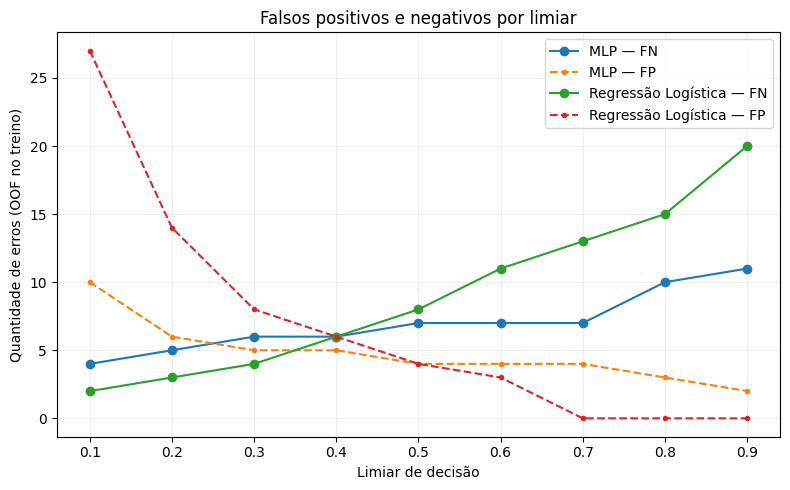

In [5]:
# Construí um gráfico para observar como o número de falsos negativos e falsos positivos
# muda conforme o limiar. As linhas contínuas representam FN e as tracejadas representam FP.

fig, ax = plt.subplots(figsize=(8, 5))
# Separei os registros por modelo para desenhar suas curvas no mesmo gráfico.
for nome, fatia in tabela_cv.groupby('modelo'):
    ax.plot(fatia['limiar'], fatia['FN'], marker='o', label=f'{nome} — FN')
    ax.plot(fatia['limiar'], fatia['FP'], linestyle='--', marker='.', label=f'{nome} — FP')
ax.set(xlabel='Limiar de decisão', ylabel='Quantidade de erros (OOF no treino)',
       title='Falsos positivos e negativos por limiar')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
# Salvei este gráfico em PNG para o GitHub e em PDF vetorial para o artigo.
fig.savefig(PASTA_RESULTADOS / 'falsos_positivos_negativos_por_limiar.png', dpi=300, bbox_inches='tight')
fig.savefig(PASTA_RESULTADOS / 'falsos_positivos_negativos_por_limiar.pdf', bbox_inches='tight')
plt.show()

## 6. Avaliação única no conjunto de teste
Treino os modelos com todos os registros de treinamento. Comparo o limiar padrão 0,5 com o limiar definido pela validação cruzada, **sem recalibrar usando o teste**.

**Por que reservei o teste:** escolhi os limiares sem utilizar as 114 amostras de teste. Só depois ajustei os modelos com os dados de treinamento e avaliei as duas regras no teste. Assim, não seleciono o melhor limiar olhando os resultados finais.


In [6]:
# Depois da escolha dos limiares, ajustei cada modelo com todo o conjunto de treinamento.
# Avaliei o teste reservado uma única vez, comparando o limiar padrão 0,5 com o selecionado na validação.

# Aqui armazenarei os resultados das duas regras para cada modelo.
resultados_teste = []
probabilidades_teste = {}
for nome, modelo in modelos.items():
    # Reajustei o modelo usando todos os dados de treino, sem incluir o teste.
    modelo.fit(X_treino, y_treino)
    # Extraí a probabilidade da classe 1, que defini como maligna.
    prob = modelo.predict_proba(X_teste)[:, 1]
    probabilidades_teste[nome] = prob
    # Comparei o limiar padrão com o limiar selecionado na validação cruzada.
    for regra, t in [('Padrão 0,5', 0.5), ('Selecionado na CV', limiares_escolhidos[nome])]:
        resultados_teste.append({'modelo': nome, 'regra': regra,
                                 **avaliar(y_teste, prob, t)})
tabela_teste = pd.DataFrame(resultados_teste)
display(tabela_teste.round(4))

,modelo,regra,limiar,acuracia,precisao,recall,f1,roc_auc,VN,FP,FN,VP
0,Regressão Logística,"Padrão 0,5",0.5,0.9649,0.9750,0.9286,0.9512,0.9960,71,1,3,39
1,Regressão Logística,Selecionado na CV,0.3,0.9825,0.9762,0.9762,0.9762,0.9960,71,1,1,41
2,MLP,"Padrão 0,5",0.5,0.9737,0.9756,0.9524,0.9639,0.9901,71,1,2,40
3,MLP,Selecionado na CV,0.2,0.9561,0.9302,0.9524,0.9412,0.9901,69,3,2,40


## 7. Matrizes de confusão no teste
As linhas mostram a classe real e as colunas, a classe prevista (Benigno, Maligno). FN significa um tumor maligno previsto como benigno.

**Como ler cada matriz:** as linhas correspondem às classes reais e as colunas às classes previstas. Como a classe 1 representa malignidade, os falsos negativos aparecem na posição de maligno real e benigno previsto.


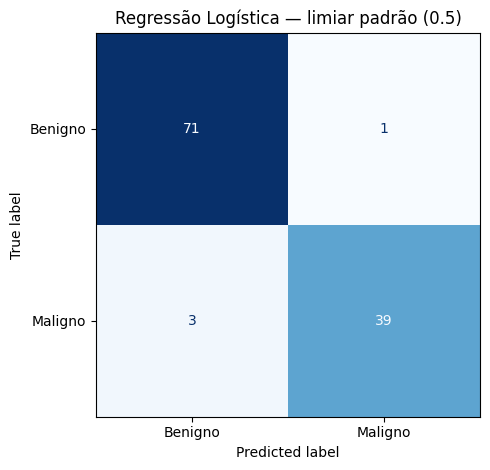

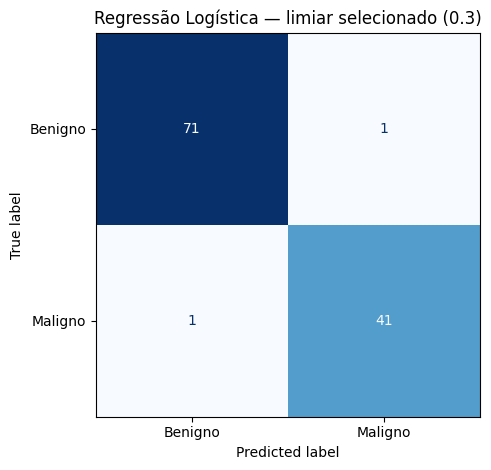

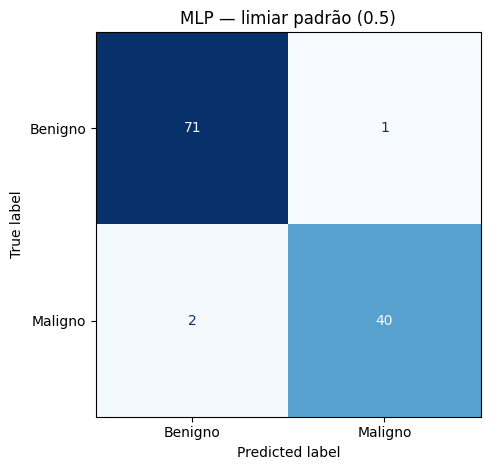

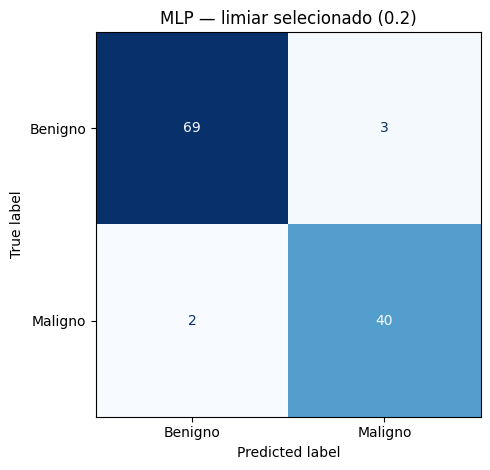

In [7]:
# Para facilitar a interpretação dos erros, gerei matrizes de confusão para cada modelo e regra.
# Nesta pesquisa, benigno é a classe 0 e maligno é a classe 1.

for nome, prob in probabilidades_teste.items():
    # Exibi uma matriz para cada uma das duas regras de limiar.
    for titulo, t in [('padrão', 0.5), ('selecionado', limiares_escolhidos[nome])]:
        # Classifiquei como maligno quando a probabilidade foi maior ou igual ao limiar.
        pred = (prob >= t).astype(int)
        exibicao = ConfusionMatrixDisplay.from_predictions(
            y_teste, pred, labels=[0, 1], display_labels=['Benigno', 'Maligno'],
            colorbar=False, cmap='Blues'
        )
        exibicao.ax_.set_title(f'{nome} — limiar {titulo} ({t:.1f})')
        fig = exibicao.figure_
        fig.tight_layout()
        # Salvei cada matriz com um nome que identifica o modelo e a regra utilizada.
        identificador = 'regressao_logistica' if 'Log' in nome else 'mlp'
        arquivo = f'matriz_confusao_{identificador}_{titulo}'
        fig.savefig(PASTA_RESULTADOS / f'{arquivo}.png', dpi=300, bbox_inches='tight')
        fig.savefig(PASTA_RESULTADOS / f'{arquivo}.pdf', bbox_inches='tight')
        plt.show()

## 8. Curvas ROC
As curvas mostram a capacidade de discriminação ao longo dos diferentes limiares, sem escolher um ponto único de operação.

**O que comparei:** representei a sensibilidade em função da taxa de falsos positivos. A ROC-AUC não muda entre o limiar padrão e o escolhido para um mesmo modelo, pois os dois usam as mesmas probabilidades previstas.


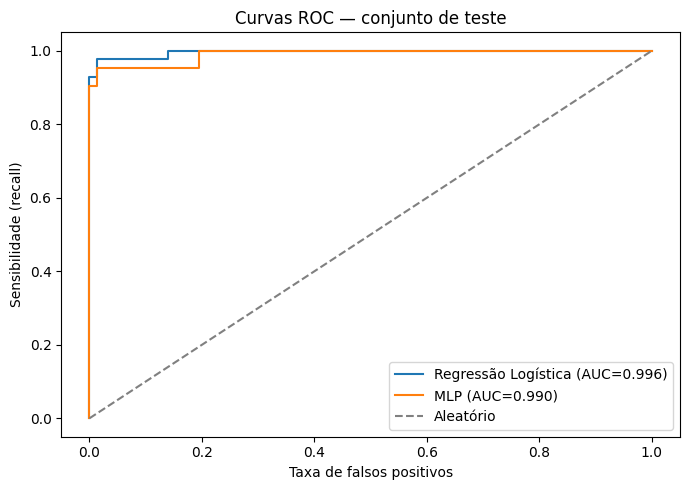

In [8]:
# Plotei as curvas ROC a partir das probabilidades previstas no teste.
# Elas permitem visualizar o compromisso entre sensibilidade e taxa de falsos positivos.

fig, ax = plt.subplots(figsize=(7, 5))
for nome, prob in probabilidades_teste.items():
    # Calculei os pontos da ROC em diferentes pontos de corte.
    fpr, tpr, _ = roc_curve(y_teste, prob)
    # Calculei a área sob a ROC usando as probabilidades, não as classes discretas.
    auc = roc_auc_score(y_teste, prob)
    ax.plot(fpr, tpr, label=f'{nome} (AUC={auc:.3f})')
ax.plot([0,1],[0,1],'--',color='gray',label='Aleatório')
ax.set_xlabel('Taxa de falsos positivos')
ax.set_ylabel('Sensibilidade (recall)')
ax.set_title('Curvas ROC — conjunto de teste')
ax.legend()
fig.tight_layout()
# Salvei as curvas ROC nos formatos PNG e PDF.
fig.savefig(PASTA_RESULTADOS / 'curvas_roc.png', dpi=300, bbox_inches='tight')
fig.savefig(PASTA_RESULTADOS / 'curvas_roc.pdf', bbox_inches='tight')
plt.show()

## 9. Exportação para o artigo e GitHub
As tabelas a seguir permitem documentar os valores efetivamente obtidos nesta execução.

**Para manter a consistência:** os CSVs são gerados pelo próprio notebook.

In [9]:
# Por último, exportei as tabelas em CSV para usar os valores no artigo e no GitHub.
# Assim, posso conferir as métricas diretamente da execução e evitar transcrevê-las incorretamente.

# Salvei a análise dos limiares feita na validação cruzada.
tabela_cv.to_csv(PASTA_RESULTADOS / 'n2_validacao_limiares.csv', index=False)
# Salvei os resultados finais do teste reservado.
tabela_teste.to_csv(PASTA_RESULTADOS / 'n2_resultados_teste.csv', index=False)
print('Tabelas exportadas para a pasta resultados.')
print('Arquivos gerados nesta execução:')
for caminho in sorted(PASTA_RESULTADOS.iterdir()):
    if caminho.is_file():
        print('-', caminho.name)

Tabelas exportadas para a pasta resultados.
Arquivos gerados nesta execução:
- curvas_roc.pdf
- curvas_roc.png
- falsos_positivos_negativos_por_limiar.pdf
- falsos_positivos_negativos_por_limiar.png
- matriz_confusao_mlp_padrão.pdf
- matriz_confusao_mlp_padrão.png
- matriz_confusao_mlp_selecionado.pdf
- matriz_confusao_mlp_selecionado.png
- matriz_confusao_regressao_logistica_padrão.pdf
- matriz_confusao_regressao_logistica_padrão.png
- matriz_confusao_regressao_logistica_selecionado.pdf
- matriz_confusao_regressao_logistica_selecionado.png
- n2_resultados_teste.csv
- n2_validacao_limiares.csv



## 10. Discussão dos resultados e limitações

Nesta etapa, analisei os resultados obtidos pelos dois modelos, buscando compreender como a alteração do limiar de decisão influenciou a identificação de tumores malignos. Considerei principalmente os falsos negativos, os falsos positivos, o recall, o F1-score e a ROC-AUC.

### 10.1 Influência do limiar nos falsos negativos

Na Regressão Logística, a redução do limiar de 0,5 para 0,3 diminuiu a quantidade de falsos negativos de 3 para 1, mantendo apenas 1 falso positivo.

Isso significa que o modelo passou a identificar corretamente dois casos malignos que anteriormente eram classificados como benignos.

Na MLP, entretanto, a redução do limiar de 0,5 para 0,2 não apresentou o mesmo benefício. O modelo continuou com 2 falsos negativos, enquanto os falsos positivos aumentaram de 1 para 3.

Assim, observei que a diminuição do limiar não necessariamente melhora o resultado de todos os modelos.

### 10.2 Comparação das métricas

Na Regressão Logística, o recall aumentou de 92,86% para 97,62%, enquanto o F1-score passou de 95,12% para 97,62%.

Na MLP, o recall permaneceu em 95,24%, mas o F1-score diminuiu de 96,39% para 94,12%, devido ao aumento dos falsos positivos e à redução da precisão.

A ROC-AUC permaneceu constante dentro de cada modelo: aproximadamente 0,996 na Regressão Logística e 0,990 na MLP.

Isso acontece porque a ROC-AUC foi calculada utilizando as probabilidades previstas, enquanto a alteração do limiar modifica apenas a classificação final das amostras. Como as probabilidades não foram alteradas, a ROC-AUC também permaneceu igual.

### 10.3 Comparação entre os modelos

Considerando o conjunto de teste utilizado, a Regressão Logística com limiar 0,3 apresentou o melhor F1-score (97,62%) e o menor número de falsos negativos (1).

A MLP com limiar padrão de 0,5 também apresentou bom desempenho, com F1-score de 96,39% e 2 falsos negativos.

Entretanto, a diferença observada não é suficiente para afirmar que a Regressão Logística seja superior à MLP em qualquer situação.

Os resultados correspondem a um único conjunto de teste, com apenas 114 amostras, e não foram realizados testes de significância estatística.

### 10.4 Limitações do experimento

Apesar dos resultados obtidos, identifiquei algumas limitações importantes.

Primeiramente, utilizei apenas o conjunto Breast Cancer Wisconsin Diagnostic, composto por 569 amostras. Embora seja adequado para um experimento acadêmico, ele não representa toda a diversidade de situações encontradas em aplicações clínicas reais.

Além disso, utilizei validação cruzada interna para selecionar os limiares e um único conjunto reservado para a avaliação final. Diferentes divisões dos dados poderiam produzir resultados distintos.

Também não realizei uma análise de custo clínico dos erros. A escolha do limiar pelo maior F1-score considera uma métrica estatística, mas não determina automaticamente a melhor decisão em um contexto médico.

Por fim, os experimentos foram realizados com configurações específicas dos modelos, sem uma investigação extensa de hiperparâmetros.

### 10.5 Considerações finais

Com este experimento, consegui observar que a escolha do limiar de decisão influencia diretamente os resultados de classificação, especialmente a quantidade de falsos positivos e falsos negativos.

No conjunto analisado, a Regressão Logística apresentou melhora após o ajuste do limiar, enquanto a MLP não apresentou redução nos falsos negativos com o limiar selecionado.

Esses resultados reforçam a importância de avaliar diferentes métricas, em vez de considerar apenas a acurácia, e mostram que a escolha do limiar deve ser analisada individualmente para cada modelo.

O estudo possui finalidade exclusivamente acadêmica e não permite concluir que os modelos estejam preparados para aplicações de diagnóstico médico.

**Pesquisa bibliográfica e uso de IA:** utilizei o Hermes Agent para auxiliar na localização e triagem inicial de referências científicas. O levantamento contribuiu para a definição do problema e da metodologia experimental.


In [10]:

import os
import zipfile
from google.colab import files

# Compactei os arquivos da pasta resultados para
# conseguir baixar tudo de uma só vez.

pasta = "resultados"
arquivo_zip = "resultados_n2_ia.zip"

if not os.path.isdir(pasta) or not os.listdir(pasta):
    raise RuntimeError('A pasta resultados está vazia. Execute todas as células anteriores primeiro.')

with zipfile.ZipFile(arquivo_zip, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for raiz, diretorios, arquivos in os.walk(pasta):
        for arquivo in arquivos:
            caminho = os.path.join(raiz, arquivo)
            zipf.write(caminho, arcname=os.path.join(pasta, os.path.relpath(caminho, pasta)))

# Baixei o arquivo ZIP com os resultados do experimento.
files.download(arquivo_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>